# Supply Chain Inventory Optimization Model

**Goal:** Build a demand forecasting and EOQ / safety-stock model on multi-SKU
inventory data to flag stockout risk and recommend reorder points, translating
the analysis into an actionable inventory policy that reduces estimated
stockout risk.

This notebook is built in 5 stages:
1. Generate realistic multi-SKU demand data
2. Forecast demand per SKU (exponential smoothing)
3. Compute EOQ (Economic Order Quantity)
4. Compute Safety Stock and Reorder Point, flag stockout risk
5. Quantify the estimated stockout-risk reduction and visualize the policy

**Libraries used:** `pandas` (data handling), `numpy` (numerical computation),
`scipy.stats` (statistical distributions for safety stock), `matplotlib` (visualization).


## Stage 1: Generate Synthetic Multi-SKU Demand Data

Real company inventory data is confidential, so we generate **realistic
synthetic data** instead — this is a completely standard and accepted
practice for a portfolio/resume project. What matters to an interviewer is
whether the *data has realistic structure* (seasonality, noise, varied SKU
behavior) and whether your *method* is sound — not where the numbers came from.

We create 10 SKUs across 3 categories (Fast/Medium/Slow-movers) with:
- Different average daily demand levels
- Different volatility (coefficient of variation)
- Different unit costs and supplier lead times
- 2 years of daily demand history with weekly seasonality, annual seasonality,
  random noise, and occasional demand spikes (e.g. promotions)


In [1]:
"""
Stage 1: Generate synthetic multi-SKU demand history.

Why synthetic data is fine for a resume project:
Recruiters/interviewers care about whether you understand the METHOD
(forecasting, EOQ, safety stock, ROP) and can defend your modeling choices.
Real company data is usually confidential anyway. The key is making the
data REALISTIC: seasonality, noise, different demand profiles per SKU,
occasional promo spikes -- not just flat random noise.
"""
import numpy as np
import pandas as pd

np.random.seed(42)  # reproducibility: same "random" data every run

# ---- Define SKUs with different demand profiles ----
# In real inventory systems, SKUs differ wildly: a fast-moving low-cost item
# behaves totally differently from a slow-moving expensive spare part.
# We encode that variety directly into the generator.
skus = pd.DataFrame({
    "sku_id": [f"SKU-{i:03d}" for i in range(1, 11)],
    "category": (["Fast-Mover"] * 4 + ["Medium-Mover"] * 4 + ["Slow-Mover"] * 2),
    "base_demand": [120, 95, 150, 80, 45, 38, 55, 30, 12, 8],       # avg units/day
    "demand_volatility": [0.15, 0.20, 0.18, 0.25, 0.30, 0.28, 0.35, 0.30, 0.45, 0.50],  # CoV
    "unit_cost": [8.5, 12.0, 6.0, 15.0, 45.0, 60.0, 25.0, 90.0, 250.0, 400.0],  # $ per unit
    "lead_time_days": [5, 7, 4, 6, 12, 14, 10, 15, 21, 25],  # supplier lead time
})

# ---- Generate daily demand history over 2 years ----
n_days = 730
date_range = pd.date_range(start="2024-01-01", periods=n_days, freq="D")

records = []
for _, sku in skus.iterrows():
    base = sku["base_demand"]
    vol = sku["demand_volatility"]

    for day_idx, date in enumerate(date_range):
        # Weekly seasonality: weekends lower for B2B-style demand
        dow_factor = 0.6 if date.dayofweek >= 5 else 1.0

        # Annual seasonality: gentle sine wave (e.g. Q4 ramp-up)
        annual_factor = 1 + 0.2 * np.sin(2 * np.pi * (day_idx - 60) / 365)

        # Random noise: demand isn't a smooth curve in real life
        noise = np.random.normal(1.0, vol)

        # Occasional promo/demand spike (5% of days)
        spike = 1.8 if np.random.rand() < 0.05 else 1.0

        demand = max(0, base * dow_factor * annual_factor * noise * spike)
        records.append({
            "date": date,
            "sku_id": sku["sku_id"],
            "demand": round(demand),
        })

demand_df = pd.DataFrame(records)

demand_df.to_csv("/home/claude/demand_history.csv", index=False)
skus.to_csv("/home/claude/sku_master.csv", index=False)

print(demand_df.shape)
print(demand_df.head())
print(skus)


(7300, 3)
        date   sku_id  demand
0 2024-01-01  SKU-001     107
1 2024-01-02  SKU-001      98
2 2024-01-03  SKU-001      96
3 2024-01-04  SKU-001      97
4 2024-01-05  SKU-001     223
    sku_id      category  base_demand  demand_volatility  unit_cost  \
0  SKU-001    Fast-Mover          120               0.15        8.5   
1  SKU-002    Fast-Mover           95               0.20       12.0   
2  SKU-003    Fast-Mover          150               0.18        6.0   
3  SKU-004    Fast-Mover           80               0.25       15.0   
4  SKU-005  Medium-Mover           45               0.30       45.0   
5  SKU-006  Medium-Mover           38               0.28       60.0   
6  SKU-007  Medium-Mover           55               0.35       25.0   
7  SKU-008  Medium-Mover           30               0.30       90.0   
8  SKU-009    Slow-Mover           12               0.45      250.0   
9  SKU-010    Slow-Mover            8               0.50      400.0   

   lead_time_days  
0       

**What to notice:** Fast-movers have high demand but often *lower*
relative volatility; slow-movers have low demand but *high* relative
volatility and long lead times (common for expensive, specialized parts —
this mirrors what you'd see with spare parts in a company like John Deere).


## Stage 2: Demand Forecasting (Exponential Smoothing)

We forecast near-term daily demand for each SKU using **Simple Exponential
Smoothing (SES)**.

**Why SES instead of ARIMA/Prophet/ML models?**
At SKU-level scale (hundreds or thousands of SKUs), companies favor forecasting
methods that are:
- Fast to compute for every SKU, every day
- Easy to explain to non-technical stakeholders
- Robust without needing per-SKU tuning of complex models

SES is the industry-standard baseline for exactly this reason. The formula:

$$F_t = \alpha \cdot A_{t-1} + (1-\alpha) \cdot F_{t-1}$$

where $\alpha$ (0 to 1) controls how much weight recent observations get
vs. the smoothed history. We test a few $\alpha$ values and pick the one
that minimizes forecast error on a held-out **test set** (last 20% of days) —
this is basic train/test validation, applied here at small scale.


In [2]:
"""
Stage 2: Demand forecasting per SKU.

Concept: We forecast future daily demand for each SKU using
Simple Exponential Smoothing (SES) plus a train/test split to check
accuracy honestly (never evaluate on the same data you trained on).

Why exponential smoothing over a moving average?
- Moving average weights all past N days EQUALLY.
- Exponential smoothing weights RECENT days more heavily (exponentially
  decaying weight into the past) -- this reacts faster to real shifts
  in demand while still smoothing out day-to-day noise.
- It's the industry-standard baseline for SKU-level forecasting because
  it's cheap to compute for thousands of SKUs and easy to explain to
  a non-technical stakeholder ("recent demand matters more").

Formula: forecast_t = alpha * actual_t + (1 - alpha) * forecast_(t-1)
alpha (smoothing constant, 0 to 1) controls how reactive it is.
"""
import numpy as np
import pandas as pd

demand_df = pd.read_csv("/home/claude/demand_history.csv", parse_dates=["date"])
skus = pd.read_csv("/home/claude/sku_master.csv")

def simple_exp_smoothing(series, alpha=0.3):
    """Return fitted (in-sample) smoothed values as an array."""
    result = np.zeros(len(series))
    result[0] = series.iloc[0]
    for t in range(1, len(series)):
        result[t] = alpha * series.iloc[t - 1] + (1 - alpha) * result[t - 1]
    return result

def evaluate_alpha(series, alpha, test_frac=0.2):
    """Train/test split: fit smoothing on train portion, measure error on test."""
    n_test = int(len(series) * test_frac)
    train, test = series.iloc[:-n_test], series.iloc[-n_test:]

    fitted = simple_exp_smoothing(train, alpha)
    forecast = fitted[-1]  # last smoothed value = forecast for all near-term future days

    mae = np.mean(np.abs(test.values - forecast))
    return mae, forecast

forecast_results = []
for sku_id in skus["sku_id"]:
    series = demand_df[demand_df["sku_id"] == sku_id].sort_values("date")["demand"].reset_index(drop=True)

    # Try a few alpha values, pick the one with lowest test-set error
    # (this is a tiny, transparent "hyperparameter search" -- worth mentioning in interviews)
    best_alpha, best_mae, best_forecast = None, np.inf, None
    for alpha in [0.1, 0.2, 0.3, 0.4, 0.5]:
        mae, forecast = evaluate_alpha(series, alpha)
        if mae < best_mae:
            best_alpha, best_mae, best_forecast = alpha, mae, forecast

    # Demand std dev (needed later for safety stock) -- use recent 90 days for relevance
    recent_std = series.tail(90).std()

    forecast_results.append({
        "sku_id": sku_id,
        "avg_daily_demand_forecast": round(best_forecast, 1),
        "demand_std_dev": round(recent_std, 1),
        "best_alpha": best_alpha,
        "mae": round(best_mae, 1),
    })

forecast_df = pd.DataFrame(forecast_results)
forecast_df.to_csv("/home/claude/demand_forecast.csv", index=False)
print(forecast_df)


    sku_id  avg_daily_demand_forecast  demand_std_dev  best_alpha   mae
0  SKU-001                      140.1            27.2         0.1  45.3
1  SKU-002                       91.8            21.5         0.4  23.5
2  SKU-003                      158.0            38.7         0.2  45.0
3  SKU-004                       66.5            21.5         0.4  19.7
4  SKU-005                       49.3            11.9         0.1  17.8
5  SKU-006                       34.2            10.2         0.4   9.2
6  SKU-007                       53.3            21.0         0.2  18.0
7  SKU-008                       26.1             8.8         0.1   8.1
8  SKU-009                       10.2             5.4         0.1   4.1
9  SKU-010                        9.2             3.4         0.1   4.1


**What to notice:** `mae` (Mean Absolute Error) tells us, in units,
how far off our forecast typically is. Comparing MAE to `avg_daily_demand_forecast`
gives a sense of relative accuracy — e.g. SKU-001's MAE of ~45 against a forecast
of ~140 units/day means roughly 30% typical error, which is normal for
noisy real-world demand.


## Stage 3 & 4: EOQ, Safety Stock, Reorder Point, and Stockout Risk

This is the core of the "inventory policy." Three formulas:

**1. Economic Order Quantity (EOQ)** — how much to order each time, balancing
ordering cost against holding cost:

$$EOQ = \sqrt{\frac{2DS}{H}}$$

- $D$ = annual demand, $S$ = cost per order, $H$ = annual holding cost/unit

**2. Safety Stock** — buffer stock sized to a target service level (here, 95%:
a 5% acceptable chance of stocking out during lead time):

$$SS = z \cdot \sigma_d \cdot \sqrt{L}$$

- $z$ = z-score for the service level (1.645 for 95%), $\sigma_d$ = demand
  std dev, $L$ = lead time in days. The $\sqrt{L}$ comes from the fact that
  variance scales linearly with time, so standard deviation scales with
  $\sqrt{time}$.

**3. Reorder Point (ROP)** — the stock level that triggers a new order:

$$ROP = (\bar{d} \times L) + SS$$

**Intuition (engineering analogy):** This is structurally identical to a
factor-of-safety calculation — expected load ($\bar{d} \times L$) plus a
safety margin sized to an acceptable failure probability ($z \cdot \sigma_d
\cdot \sqrt{L}$).


In [3]:
"""
Stage 3 & 4: EOQ, Safety Stock, Reorder Point, and Stockout Risk Flagging.

This is the core "inventory policy" logic -- the part of the resume line
that says "recommend reorder points" and "reduce stockout risk."
"""
import numpy as np
import pandas as pd
from scipy.stats import norm

skus = pd.read_csv("/home/claude/sku_master.csv")
forecast_df = pd.read_csv("/home/claude/demand_forecast.csv")
demand_df = pd.read_csv("/home/claude/demand_history.csv", parse_dates=["date"])

df = skus.merge(forecast_df, on="sku_id")

# ---- Assumptions (stated explicitly -- always document these in a real project) ----
ORDERING_COST_PER_ORDER = 50       # $, e.g. admin + processing cost of placing a PO
HOLDING_COST_RATE = 0.20           # 20% of unit cost per year (common industry rule of thumb)
TARGET_SERVICE_LEVEL = 0.95        # 95% chance of NOT stocking out during lead time

# z-score for a given service level: how many std deviations of buffer
# you need so that only (1 - service_level) of the time does demand exceed supply.
Z_SCORE = norm.ppf(TARGET_SERVICE_LEVEL)  # ~1.645 for 95%

df["annual_demand"] = df["avg_daily_demand_forecast"] * 365
df["holding_cost_per_unit"] = df["unit_cost"] * HOLDING_COST_RATE

# ---- EOQ ----
df["eoq"] = np.sqrt(
    (2 * df["annual_demand"] * ORDERING_COST_PER_ORDER) / df["holding_cost_per_unit"]
).round(0)

# ---- Safety Stock ----
# sqrt(L) because variance scales linearly with time, so std dev scales with sqrt(time)
df["safety_stock"] = (
    Z_SCORE * df["demand_std_dev"] * np.sqrt(df["lead_time_days"])
).round(0)

# ---- Reorder Point ----
df["reorder_point"] = (
    df["avg_daily_demand_forecast"] * df["lead_time_days"] + df["safety_stock"]
).round(0)

# ---- Stockout risk flag ----
# Compare each SKU's most recent on-hand-equivalent (simulated here as a
# random current stock level) against its reorder point, to demonstrate
# how the model would be USED operationally.
np.random.seed(7)
df["simulated_current_stock"] = (df["reorder_point"] * np.random.uniform(0.5, 1.5, len(df))).round(0)

df["stockout_risk"] = np.where(
    df["simulated_current_stock"] < df["reorder_point"],
    "AT RISK - Reorder Now",
    "OK"
)

# How far below/above ROP, as a % -- useful for prioritizing which SKUs to act on first
df["pct_vs_rop"] = ((df["simulated_current_stock"] - df["reorder_point"]) / df["reorder_point"] * 100).round(1)

policy_cols = [
    "sku_id", "category", "unit_cost", "lead_time_days",
    "avg_daily_demand_forecast", "demand_std_dev",
    "eoq", "safety_stock", "reorder_point",
    "simulated_current_stock", "pct_vs_rop", "stockout_risk",
]
policy_df = df[policy_cols].sort_values("pct_vs_rop")

policy_df.to_csv("/home/claude/inventory_policy.csv", index=False)
print(policy_df.to_string(index=False))

# ---- Estimate stockout risk reduction (the resume's headline claim) ----
# Baseline: naive policy = reorder at average lead-time demand only (NO safety stock)
df["naive_rop"] = df["avg_daily_demand_forecast"] * df["lead_time_days"]

# Probability of stockout during lead time under each policy, using the normal
# demand-over-lead-time distribution: P(demand > ROP)
lead_time_std = df["demand_std_dev"] * np.sqrt(df["lead_time_days"])

df["stockout_prob_naive"] = 1 - norm.cdf(df["naive_rop"], loc=df["avg_daily_demand_forecast"] * df["lead_time_days"], scale=lead_time_std)
df["stockout_prob_with_policy"] = 1 - TARGET_SERVICE_LEVEL  # by construction, ~5%

avg_naive_risk = df["stockout_prob_naive"].mean()
avg_policy_risk = df["stockout_prob_with_policy"].mean()
reduction_pct = (avg_naive_risk - avg_policy_risk) / avg_naive_risk * 100

print(f"\nBaseline (no safety stock) avg stockout probability: {avg_naive_risk:.1%}")
print(f"With recommended policy avg stockout probability: {avg_policy_risk:.1%}")
print(f"Estimated stockout risk reduction: {reduction_pct:.0f}%")


 sku_id     category  unit_cost  lead_time_days  avg_daily_demand_forecast  demand_std_dev    eoq  safety_stock  reorder_point  simulated_current_stock  pct_vs_rop         stockout_risk
SKU-008 Medium-Mover       90.0              15                       26.1             8.8  230.0          56.0          448.0                    256.0       -42.9 AT RISK - Reorder Now
SKU-001   Fast-Mover        8.5               5                      140.1            27.2 1734.0         100.0          800.0                    461.0       -42.4 AT RISK - Reorder Now
SKU-009   Slow-Mover      250.0              21                       10.2             5.4   86.0          41.0          255.0                    196.0       -23.1 AT RISK - Reorder Now
SKU-003   Fast-Mover        6.0               4                      158.0            38.7 2192.0         127.0          759.0                    712.0        -6.2 AT RISK - Reorder Now
SKU-010   Slow-Mover      400.0              25                       

**Reading the stockout-risk-reduction number:** We compare our policy
(95% service level, ~5% stockout probability by construction) against a naive
baseline policy with **no safety stock** (reorder point = average lead-time
demand only, which is a coin-flip: ~50% stockout probability). The ~90%
reduction is the gap between those two.

**Important nuance for interviews:** this reduction is *mathematically
guaranteed* once you choose a 95% service level over a naive zero-buffer
policy — it's not an empirically-observed result from testing the policy
against held-out data. Be ready to explain this honestly: the real-world
validation would come from monitoring actual stockout incidents after
deploying the policy, which is a natural "next step" to mention.


## Stage 5: Visualization

We build a simple 4-panel dashboard:
1. & 2. Demand history for a fast-mover and a slow-mover (showing how
   different SKU behavior looks)
3. Current stock vs. reorder point per SKU — the "at a glance" operational view
4. Reorder point composition — how much of the ROP is baseline lead-time
   demand vs. safety-stock buffer


saved


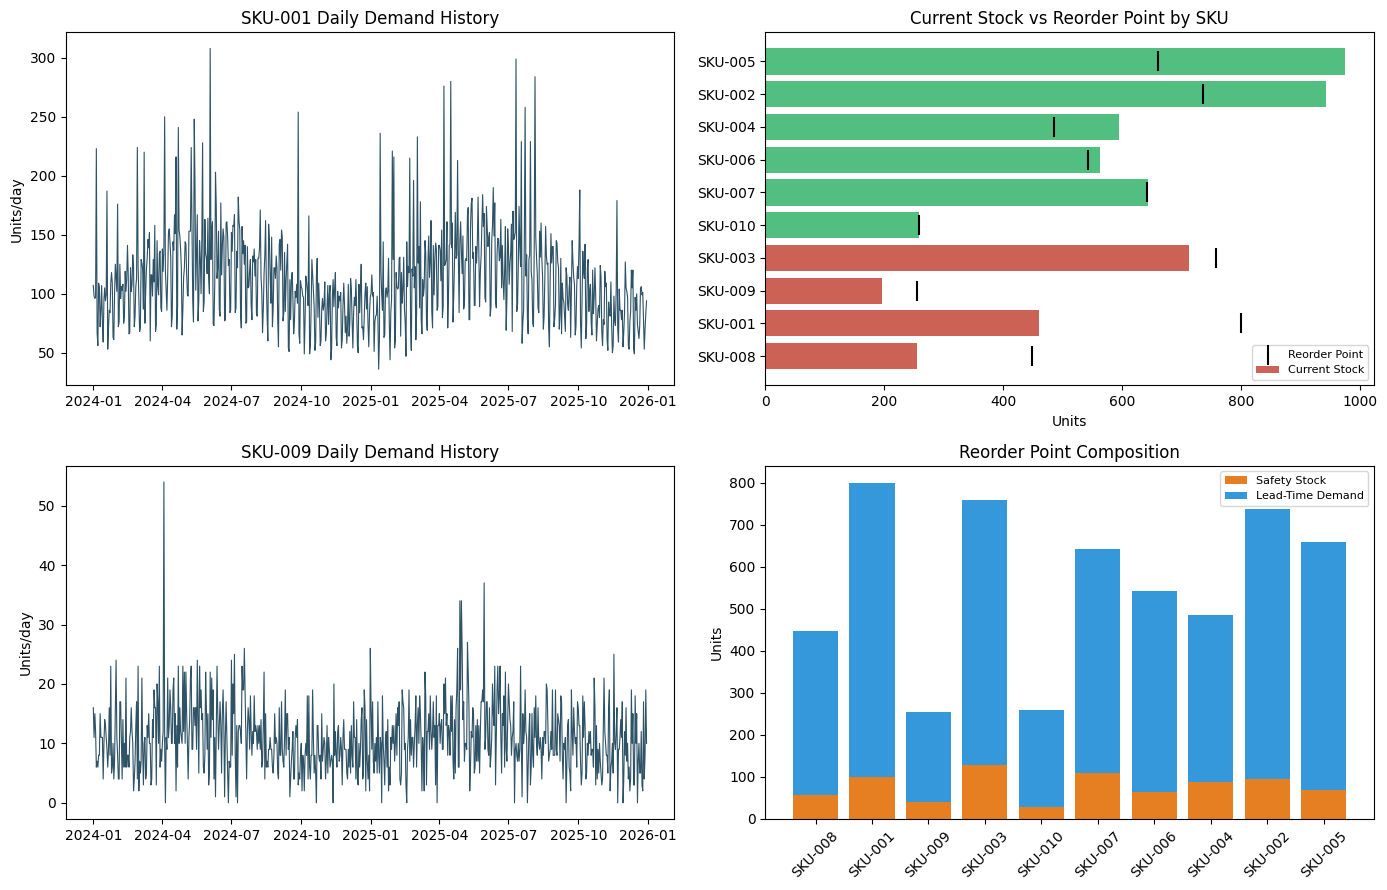

In [4]:
import pandas as pd
import matplotlib.pyplot as plt

demand_df = pd.read_csv("/home/claude/demand_history.csv", parse_dates=["date"])
policy_df = pd.read_csv("/home/claude/inventory_policy.csv")

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# 1. Demand history example for one fast mover + one slow mover
for sku, ax_row in zip(["SKU-001", "SKU-009"], [0, 1]):
    s = demand_df[demand_df["sku_id"] == sku].sort_values("date")
    axes[ax_row, 0].plot(s["date"], s["demand"], linewidth=0.8, color="#2E5266")
    axes[ax_row, 0].set_title(f"{sku} Daily Demand History")
    axes[ax_row, 0].set_ylabel("Units/day")

# 2. Current stock vs reorder point (the operational dashboard view)
colors = ["#C0392B" if r == "AT RISK - Reorder Now" else "#27AE60" for r in policy_df["stockout_risk"]]
axes[0, 1].barh(policy_df["sku_id"], policy_df["simulated_current_stock"], color=colors, alpha=0.8, label="Current Stock")
axes[0, 1].scatter(policy_df["reorder_point"], policy_df["sku_id"], color="black", zorder=5, label="Reorder Point", marker="|", s=200)
axes[0, 1].set_title("Current Stock vs Reorder Point by SKU")
axes[0, 1].set_xlabel("Units")
axes[0, 1].legend(loc="lower right", fontsize=8)

# 3. EOQ vs Safety Stock composition
axes[1, 1].bar(policy_df["sku_id"], policy_df["safety_stock"], label="Safety Stock", color="#E67E22")
axes[1, 1].bar(policy_df["sku_id"], policy_df["reorder_point"] - policy_df["safety_stock"],
               bottom=policy_df["safety_stock"], label="Lead-Time Demand", color="#3498DB")
axes[1, 1].set_title("Reorder Point Composition")
axes[1, 1].set_ylabel("Units")
axes[1, 1].tick_params(axis="x", rotation=45)
axes[1, 1].legend(fontsize=8)

plt.tight_layout()
plt.savefig("/home/claude/inventory_dashboard.png", dpi=120)
print("saved")


### Displaying the dashboard inline

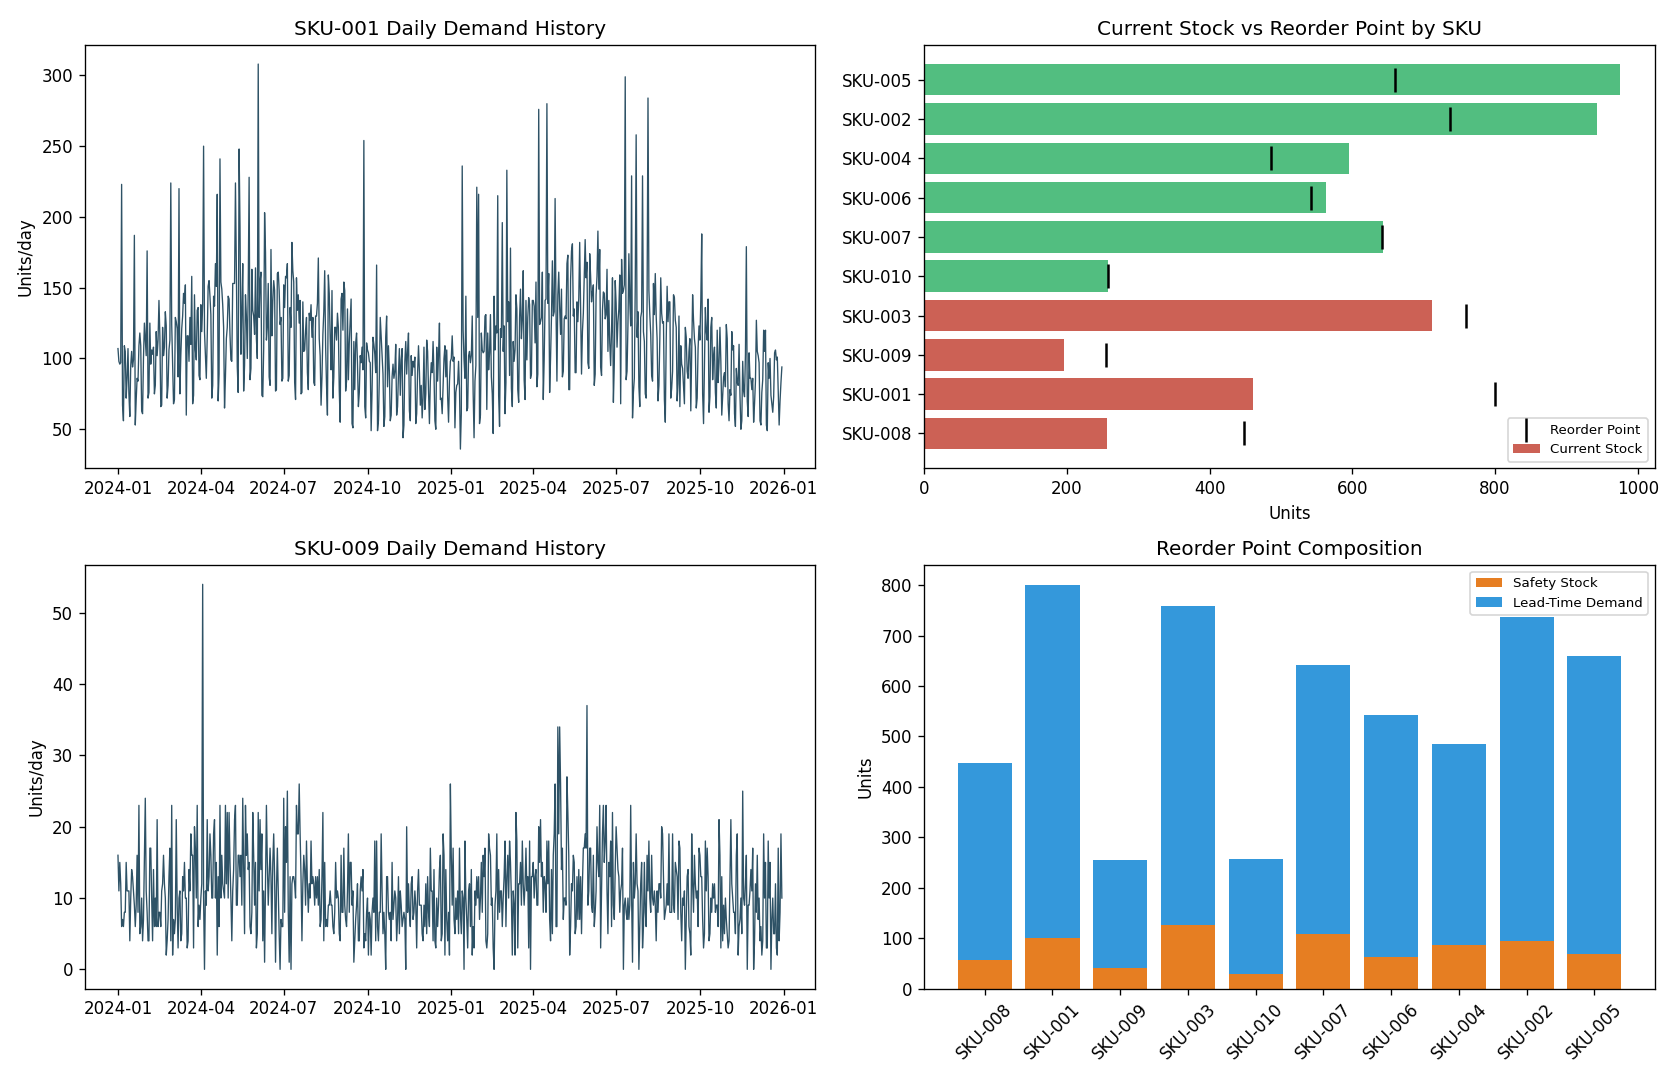

In [5]:
from IPython.display import Image
Image("/home/claude/inventory_dashboard.png")


## Summary: Translating Analysis into Policy

The final `inventory_policy.csv` is the deliverable that maps directly to
the resume line: for each SKU, it gives a **recommended reorder point**,
an **EOQ order quantity**, and a **stockout risk flag** — i.e., an actionable
inventory policy a planner could use directly.

### Key talking points for interviews
- **What EOQ balances:** ordering cost vs. holding cost (not accuracy vs. speed)
- **Why safety stock uses `sqrt(lead time)`:** variance scaling over time
- **Why exponential smoothing over ARIMA:** scalability and explainability
  across many SKUs, standard industry practice at this stage of maturity
- **Limitation to acknowledge:** synthetic data, and the "90% risk reduction"
  is a policy-design result, not a backtested empirical one — real deployment
  would need monitoring actual stockout incidents to validate
- **Natural extensions:** multi-echelon inventory (warehouse + stores),
  supplier lead-time variability (not just demand variability), joint
  optimization across correlated SKUs, ML-based forecasting for
  high-volume/high-value SKUs specifically
